# Is the Great Stay Ending? Quits, Hires, and Job Openings by Industry, 2019 to Today

**Author:** Chinekwu Paulin Enwonwu

This notebook uses the Bureau of Labor Statistics Job Openings and Labor Turnover Survey (JOLTS) to track how
hiring, quitting, and job openings have changed since before the pandemic, overall and by industry.

**Questions**
1. How far have quits, hires, and openings moved from their 2019 levels?
2. Which industries have cooled the most since the 2022 peak in quitting?
3. Are workers still switching jobs as often as before the pandemic?

**Data:** BLS Public Data API (no key needed for small requests). All rates are seasonally adjusted and
expressed as a percent of employment (openings as a percent of employment plus openings).

In [1]:
import json
from datetime import date
from pathlib import Path

import pandas as pd
import requests
import matplotlib.pyplot as plt
import plotly.express as px

OUT = Path("figures")
OUT.mkdir(exist_ok=True)

START_YEAR = 2019
END_YEAR = date.today().year
BASELINE_YEAR = 2019   # pre-pandemic benchmark
PEAK_YEAR = 2022       # year of peak quitting

## 1. Define the series

JOLTS series IDs follow the pattern `JTS` + industry code (6 digits) + state, area and size codes (zeros for
national data) + data element + `R` for rate. For example, `JTS000000000000000QUR` is the national quits rate.

In [2]:
INDUSTRIES = {
    "000000": "Total nonfarm",
    "230000": "Construction",
    "300000": "Manufacturing",
    "440000": "Retail trade",
    "510000": "Information",
    "510099": "Financial activities",
    "540099": "Professional and business services",
    "620000": "Health care and social assistance",
    "700000": "Leisure and hospitality",
    "900000": "Government",
}
MEASURES = {"QU": "Quits", "HI": "Hires", "JO": "Job openings", "LD": "Layoffs and discharges"}


def series_id(industry_code, measure_code):
    return f"JTS{industry_code}000000000{measure_code}R"


SERIES = {
    series_id(ind, m): (ind_name, m_name)
    for ind, ind_name in INDUSTRIES.items()
    for m, m_name in MEASURES.items()
}
print(f"{len(SERIES)} series requested")

40 series requested


## 2. Download the data from the BLS API

The public API allows up to 25 series per request, so the request is split into batches. The raw response is
saved to `data/jolts_raw.json` so the analysis can be rerun without downloading again.

In [3]:
API_URL = "https://api.bls.gov/publicAPI/v2/timeseries/data/"
RAW_FILE = Path("data/jolts_raw.json")
RAW_FILE.parent.mkdir(exist_ok=True)


def fetch_bls(series_ids, start_year, end_year):
    """Download BLS series in batches of 25 and return the list of series results."""
    results = []
    ids = list(series_ids)
    for i in range(0, len(ids), 25):
        payload = {"seriesid": ids[i:i + 25], "startyear": str(start_year), "endyear": str(end_year)}
        r = requests.post(API_URL, json=payload, timeout=60)
        r.raise_for_status()
        body = r.json()
        if body.get("status") != "REQUEST_SUCCEEDED":
            raise RuntimeError(f"BLS API error: {body.get('message')}")
        results.extend(body["Results"]["series"])
    return results


if RAW_FILE.exists():
    raw = json.loads(RAW_FILE.read_text())
    print(f"Loaded saved data from {RAW_FILE}")
else:
    raw = fetch_bls(SERIES.keys(), START_YEAR, END_YEAR)
    RAW_FILE.write_text(json.dumps(raw))
    print(f"Downloaded {len(raw)} series and saved to {RAW_FILE}")

Downloaded 40 series and saved to data/jolts_raw.json


## 3. Clean and reshape

Each series comes back as a list of monthly observations. I convert these into one tidy table with a date,
an industry, a measure, and a value, and flag preliminary estimates.

In [4]:
rows = []
for s in raw:
    industry, measure = SERIES[s["seriesID"]]
    for obs in s["data"]:
        if not obs["period"].startswith("M") or obs["period"] == "M13":
            continue
        value = pd.to_numeric(obs["value"], errors="coerce")
        preliminary = any(f.get("code") == "P" for f in obs.get("footnotes", []) if f)
        rows.append({
            "date": pd.Timestamp(int(obs["year"]), int(obs["period"][1:]), 1),
            "industry": industry,
            "measure": measure,
            "rate": value,
            "preliminary": preliminary,
        })

df = pd.DataFrame(rows).dropna(subset=["rate"]).sort_values(["industry", "measure", "date"]).reset_index(drop=True)

missing = sorted(set(SERIES.values()) - set(zip(df["industry"], df["measure"])))
if missing:
    print("No data returned for:", missing)

latest = df["date"].max()
print(f"{len(df):,} observations, {df['date'].min():%B %Y} to {latest:%B %Y}")
df.to_csv("data/jolts_tidy.csv", index=False)
df.head()

3,720 observations, January 2019 to September 2026


,date,industry,measure,rate,preliminary
0,2019-01-01,Construction,Hires,5.7,False
1,2019-02-01,Construction,Hires,5.0,False
2,2019-03-01,Construction,Hires,5.1,False
3,2019-04-01,Construction,Hires,5.6,False
4,2019-05-01,Construction,Hires,5.1,False


## 4. The national picture

Quits are the clearest signal of worker confidence: people quit when they are confident they can find a
better job. How do today's rates compare with 2019?

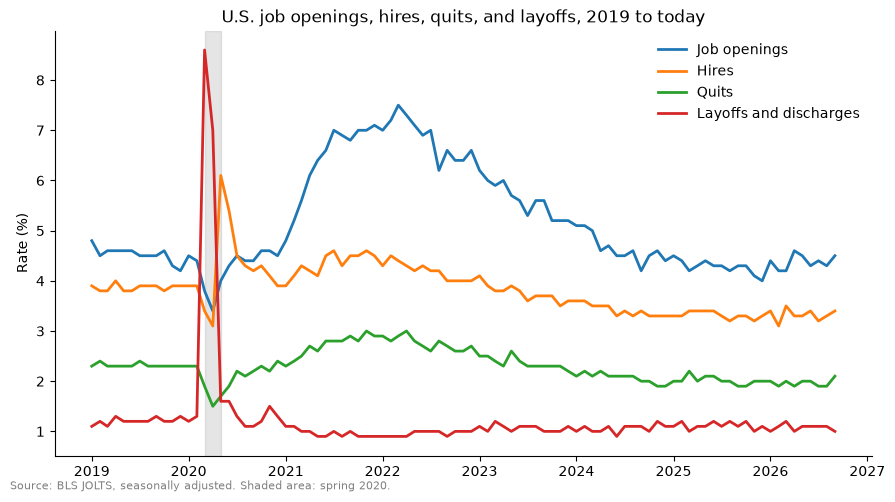

In [5]:
national = df[df["industry"] == "Total nonfarm"].pivot(index="date", columns="measure", values="rate")

fig, ax = plt.subplots(figsize=(9, 5))
for m in ["Job openings", "Hires", "Quits", "Layoffs and discharges"]:
    ax.plot(national.index, national[m], label=m, linewidth=2)
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2020-05-01"), color="grey", alpha=0.2)
ax.set_title("U.S. job openings, hires, quits, and layoffs, 2019 to today")
ax.set_ylabel("Rate (%)")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, 0.01, "Source: BLS JOLTS, seasonally adjusted. Shaded area: spring 2020.", fontsize=8, color="grey")
fig.tight_layout()
fig.savefig(OUT / "national_rates.png", dpi=200)
plt.show()

nat_long = national.reset_index().melt(id_vars="date", var_name="measure", value_name="rate")
fig_i = px.line(nat_long, x="date", y="rate", color="measure",
                title="U.S. job openings, hires, quits, and layoffs (rate, %)",
                labels={"date": "", "rate": "Rate (%)", "measure": ""})
fig_i.write_html(OUT / "national_rates.html", include_plotlyjs="cdn")
fig_i.show()

## 5. Which industries have cooled the most?

I compare each industry's quits rate over the latest 12 months with its 2019 average and with its 2022 average,
the year quitting peaked.

In [6]:
def period_mean(data, start, end):
    mask = (data["date"] >= start) & (data["date"] <= end)
    return data[mask].groupby(["industry", "measure"])["rate"].mean()


base = period_mean(df, pd.Timestamp(BASELINE_YEAR, 1, 1), pd.Timestamp(BASELINE_YEAR, 12, 1))
peak = period_mean(df, pd.Timestamp(PEAK_YEAR, 1, 1), pd.Timestamp(PEAK_YEAR, 12, 1))
recent = period_mean(df, latest - pd.DateOffset(months=11), latest)

summary = pd.DataFrame({f"{BASELINE_YEAR} avg": base, f"{PEAK_YEAR} avg": peak, "Last 12 months": recent})
summary["Change vs 2019"] = summary["Last 12 months"] - summary[f"{BASELINE_YEAR} avg"]
summary["Change vs 2022"] = summary["Last 12 months"] - summary[f"{PEAK_YEAR} avg"]
summary = summary.round(2)

quits = summary.xs("Quits", level="measure").sort_values("Change vs 2019")
quits

,2019 avg,2022 avg,Last 12 months,Change vs 2019,Change vs 2022
industry,,,,,
Professional and business services,3.03,3.34,2.05,-0.98,-1.29
Leisure and hospitality,4.63,5.47,3.88,-0.75,-1.58
Construction,2.32,2.38,1.73,-0.58,-0.65
Retail trade,3.33,3.93,2.92,-0.41,-1.01
Total nonfarm,2.32,2.76,1.97,-0.35,-0.79
Information,1.60,1.66,1.27,-0.33,-0.39
Financial activities,1.47,1.67,1.17,-0.30,-0.51
Manufacturing,1.63,2.32,1.42,-0.22,-0.90
Health care and social assistance,2.00,2.62,1.91,-0.09,-0.71


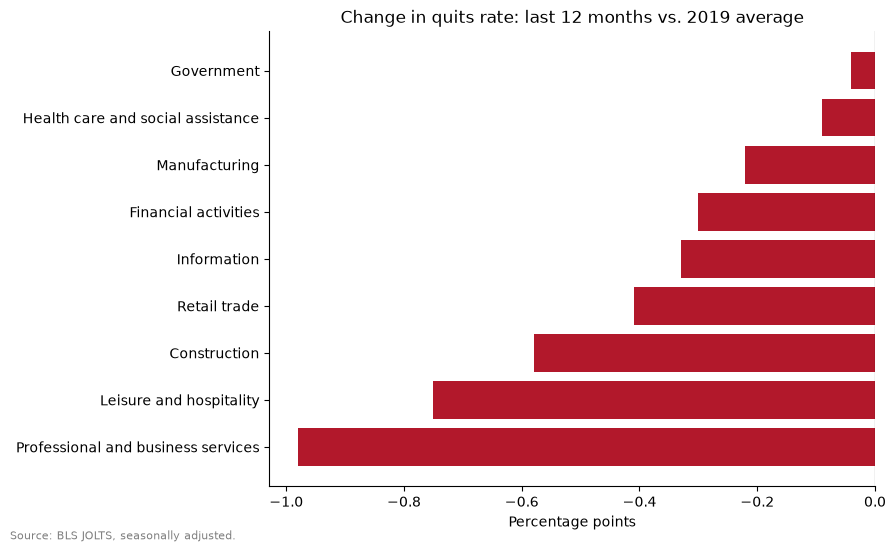

In [7]:
plot_q = quits.drop(index="Total nonfarm", errors="ignore").reset_index()

fig, ax = plt.subplots(figsize=(9, 5.5))
colors = ["#b2182b" if v < 0 else "#2166ac" for v in plot_q["Change vs 2019"]]
ax.barh(plot_q["industry"], plot_q["Change vs 2019"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Change in quits rate: last 12 months vs. 2019 average")
ax.set_xlabel("Percentage points")
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, 0.01, "Source: BLS JOLTS, seasonally adjusted.", fontsize=8, color="grey")
fig.tight_layout()
fig.savefig(OUT / "quits_change_by_industry.png", dpi=200)
plt.show()

fig_i = px.bar(plot_q, x="Change vs 2019", y="industry", orientation="h",
               title="Change in quits rate, last 12 months vs. 2019 (percentage points)",
               labels={"industry": "", "Change vs 2019": "Percentage points"})
fig_i.write_html(OUT / "quits_change_by_industry.html", include_plotlyjs="cdn")
fig_i.show()

## 6. Openings versus quits: is demand cooling faster than worker confidence?

Each point is an industry. The horizontal axis shows how much its openings rate has changed since 2019, and
the vertical axis shows the change in its quits rate.

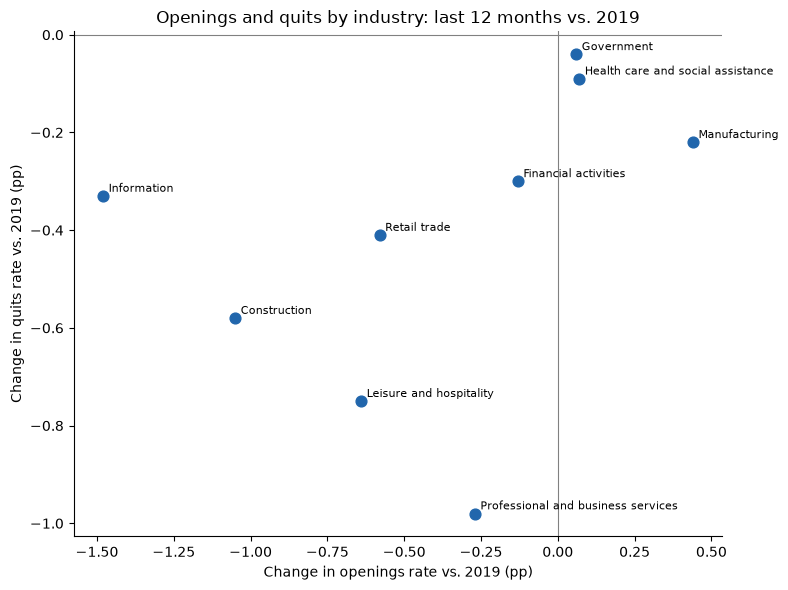

In [8]:
change = summary["Change vs 2019"].unstack("measure").drop(index="Total nonfarm", errors="ignore").reset_index()

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(change["Job openings"], change["Quits"], s=60, color="#2166ac")
for _, r in change.iterrows():
    ax.annotate(r["industry"], (r["Job openings"], r["Quits"]), fontsize=8,
                xytext=(4, 3), textcoords="offset points")
ax.axhline(0, color="grey", linewidth=0.8)
ax.axvline(0, color="grey", linewidth=0.8)
ax.set_xlabel("Change in openings rate vs. 2019 (pp)")
ax.set_ylabel("Change in quits rate vs. 2019 (pp)")
ax.set_title("Openings and quits by industry: last 12 months vs. 2019")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(OUT / "openings_vs_quits.png", dpi=200)
plt.show()

fig_i = px.scatter(change, x="Job openings", y="Quits", text="industry",
                   title="Change in openings and quits rates by industry, last 12 months vs. 2019",
                   labels={"Job openings": "Openings rate change (pp)", "Quits": "Quits rate change (pp)"})
fig_i.update_traces(textposition="top center")
fig_i.write_html(OUT / "openings_vs_quits.html", include_plotlyjs="cdn")
fig_i.show()

## 7. Key numbers for the write-up

This cell prints the main figures in plain sentences, so the write-up uses the exact numbers from the data.

In [9]:
nat = summary.xs("Total nonfarm", level="industry")
print(f"Data through {latest:%B %Y} (most recent months are preliminary).\n")
for m in ["Quits", "Hires", "Job openings", "Layoffs and discharges"]:
    r = nat.loc[m]
    print(f"{m}: {r['Last 12 months']:.1f}% over the last 12 months, "
          f"vs. {r[f'{BASELINE_YEAR} avg']:.1f}% in 2019 and {r[f'{PEAK_YEAR} avg']:.1f}% in 2022.")

q = quits.drop(index="Total nonfarm", errors="ignore")
print(f"\nLargest drop in quits vs. 2019: {q.index[0]} ({q['Change vs 2019'].iloc[0]:+.2f} pp)")
print(f"Smallest drop or largest rise: {q.index[-1]} ({q['Change vs 2019'].iloc[-1]:+.2f} pp)")
qp = q.sort_values("Change vs 2022")
print(f"Largest cooling since 2022: {qp.index[0]} ({qp['Change vs 2022'].iloc[0]:+.2f} pp)")
summary.to_csv("data/summary_by_industry.csv")

Data through September 2026 (most recent months are preliminary).

Quits: 2.0% over the last 12 months, vs. 2.3% in 2019 and 2.8% in 2022.
Hires: 3.3% over the last 12 months, vs. 3.9% in 2019 and 4.2% in 2022.
Job openings: 4.3% over the last 12 months, vs. 4.5% in 2019 and 6.8% in 2022.
Layoffs and discharges: 1.1% over the last 12 months, vs. 1.2% in 2019 and 1.0% in 2022.

Largest drop in quits vs. 2019: Professional and business services (-0.98 pp)
Smallest drop or largest rise: Government (-0.04 pp)
Largest cooling since 2022: Leisure and hospitality (-1.58 pp)
